## Demographic Analysis
**Project:** Global Healthcare Performance & Equity Analysis
**Phase:** 2 – Data Analysis
**Task 02:** Demographic Analysis
**Analyst:** Fatima Awad

## Part A: Data Understanding & Quality Checks

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Plot style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

# Paths  
DATA_PATH = Path("integrated_healthcare_dataset.csv")
CHARTS_DIR = Path("charts")
CHARTS_DIR.mkdir(exist_ok=True)

print("Setup complete")

Setup complete


In [2]:
df_raw = pd.read_csv(DATA_PATH)

df = df_raw.copy()

print(f"Rows   : {df.shape[0]:,}")
print(f"Columns: {df.shape[1]:,}")
print()
print("All columns:")
for i, c in enumerate(df.columns, 1):
    print(f"{i:>3}. {c}")

Rows   : 12,855
Columns: 27

All columns:
  1. ISO3
  2. Country
  3. Year
  4. Population
  5. Age_0_14_Pct
  6. Age_65_Plus_Pct
  7. Urban_Population_Pct
  8. GDP_Per_Capita_PPP_2021
  9. Secondary_Enrollment_Gross_Pct
 10. Adult_Literacy_Rate
 11. Doctors_Total
 12. Doctors_Per_10k
 13. Nurses_Midwives_Per_10k
 14. Hospital_Beds_Per_10k
 15. UHC_Service_Coverage_Index
 16. Health_Exp_Per_Capita_PPP
 17. Health_Exp_Pct_GDP
 18. OOP_Pct_Current_Health_Exp
 19. Financial_Hardship_Total_Pct
 20. Large_Spending_Pct
 21. Impoverishing_Spending_Pct
 22. Q1_Poorest_Pct
 23. Q2_Pct
 24. Q3_Pct
 25. Q4_Pct
 26. Q5_Richest_Pct
 27. Equity_Gap_Pct_Points


In [3]:
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

,ISO3,Country,Year,Population,Age_0_14_Pct,Age_65_Plus_Pct,Urban_Population_Pct,GDP_Per_Capita_PPP_2021,Secondary_Enrollment_Gross_Pct,Adult_Literacy_Rate,Doctors_Total,Doctors_Per_10k,Nurses_Midwives_Per_10k,Hospital_Beds_Per_10k,UHC_Service_Coverage_Index,Health_Exp_Per_Capita_PPP,Health_Exp_Pct_GDP,OOP_Pct_Current_Health_Exp,Financial_Hardship_Total_Pct,Large_Spending_Pct,Impoverishing_Spending_Pct,Q1_Poorest_Pct,Q2_Pct,Q3_Pct,Q4_Pct,Q5_Richest_Pct,Equity_Gap_Pct_Points
0,AFG,Afghanistan,1960,"9,035,043.000",41.947,2.823,8.123,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AFG,Afghanistan,1961,"9,214,083.000",42.029,2.809,8.390,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AFG,Afghanistan,1962,"9,404,406.000",42.113,2.793,8.663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AFG,Afghanistan,1963,"9,604,487.000",42.236,2.775,8.943,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AFG,Afghanistan,1964,"9,814,318.000",42.410,2.758,9.231,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Data types:


,dtype
ISO3,object
Country,object
Year,int64
Population,float64
Age_0_14_Pct,float64
Age_65_Plus_Pct,float64
Urban_Population_Pct,float64
GDP_Per_Capita_PPP_2021,float64
Secondary_Enrollment_Gross_Pct,float64
Adult_Literacy_Rate,float64


In [4]:
DEMO_COLS = ["Population", "Age_0_14_Pct", "Age_65_Plus_Pct", "Urban_Population_Pct"]
UHC_COL = "UHC_Service_Coverage_Index"
KEY_COLS = ["ISO3", "Year"]
ANALYSIS_COLS = DEMO_COLS + [UHC_COL]


dup_count = df.duplicated(subset=KEY_COLS).sum()
print(f"Duplicated (ISO3, Year) rows: {dup_count}")

print("\nMissing in key columns:")
print(df[["ISO3", "Country", "Year"]].isna().sum())

print(f"\nUnique ISO3 codes : {df['ISO3'].nunique()}")
print(f"Unique countries  : {df['Country'].nunique()}")
print(f"Year range        : {df['Year'].min()} - {df['Year'].max()}")
print(f"Number of years   : {df['Year'].nunique()}")

Duplicated (ISO3, Year) rows: 0

Missing in key columns:
ISO3       0
Country    0
Year       0
dtype: int64

Unique ISO3 codes : 196
Unique countries  : 196
Year range        : 1960 - 2025
Number of years   : 66


In [5]:
missing_summary = pd.DataFrame({
    "N_Total": len(df),
    "N_Available": df[ANALYSIS_COLS].notna().sum(),
    "N_Missing": df[ANALYSIS_COLS].isna().sum(),
})
missing_summary["Missing_Pct"] = (missing_summary["N_Missing"] / missing_summary["N_Total"] * 100).round(2)

display(missing_summary)

,N_Total,N_Available,N_Missing,Missing_Pct
Population,12855,12774,81,0.630
Age_0_14_Pct,12855,12804,51,0.400
Age_65_Plus_Pct,12855,12804,51,0.400
Urban_Population_Pct,12855,12804,51,0.400
UHC_Service_Coverage_Index,12855,4680,8175,63.590


In [6]:
coverage_rows = []
for col in ANALYSIS_COLS:
    sub = df.loc[df[col].notna()]
    coverage_rows.append({
        "Indicator": col,
        "Observations": len(sub),
        "Countries": sub["ISO3"].nunique(),
        "First_Year": sub["Year"].min(),
        "Last_Year": sub["Year"].max(),
        "Years_With_Data": sub["Year"].nunique(),
    })

coverage = pd.DataFrame(coverage_rows).set_index("Indicator")
display(coverage)

,Observations,Countries,First_Year,Last_Year,Years_With_Data
Indicator,,,,,
Population,12774,194,1960,2025,66
Age_0_14_Pct,12804,194,1960,2025,66
Age_65_Plus_Pct,12804,194,1960,2025,66
Urban_Population_Pct,12804,194,1960,2025,66
UHC_Service_Coverage_Index,4680,195,2000,2023,24


In [7]:
demo_countries = set(df.loc[df[DEMO_COLS].notna().any(axis=1), "ISO3"])
uhc_countries = set(df.loc[df[UHC_COL].notna(), "ISO3"])
all_countries = set(df["ISO3"])

no_demo = all_countries - demo_countries
print("Countries with NO demographic data at all:")
display(df.loc[df["ISO3"].isin(no_demo), ["ISO3", "Country"]].drop_duplicates())

print("\nCountries with UHC but no Population data:")
display(df.loc[df["ISO3"].isin(uhc_countries - set(df.loc[df["Population"].notna(), "ISO3"])),
               ["ISO3", "Country"]].drop_duplicates())

agg_keywords = "World|income|Arab|Euro area|IDA|IBRD|OECD|Sub-Saharan|Asia|Latin America|Caribbean|small states|Fragile|developing|total|members"
suspect = df.loc[df["Country"].str.contains(agg_keywords, case=False, regex=True), ["ISO3", "Country"]].drop_duplicates()
print("\nPossible aggregates (check manually):")
display(suspect)

Countries with NO demographic data at all:


,ISO3,Country
2442,COK,Cook Islands
8473,NIU,Niue



Countries with UHC but no Population data:


,ISO3,Country
2442,COK,Cook Islands
8473,NIU,Niue



Possible aggregates (check manually):


,ISO3,Country
264,ARE,United Arab Emirates
9885,SAU,Saudi Arabia
11073,SYR,Syrian Arab Republic
11601,TTO,Trinidad and Tobago


In [8]:
yearly = (
    df.groupby("Year")
      .agg(
          Demo_Countries=("Age_65_Plus_Pct", lambda s: df.loc[s.index][s.notna()]["ISO3"].nunique()),
          UHC_Countries=(UHC_COL, lambda s: df.loc[s.index][s.notna()]["ISO3"].nunique()),
      )
)

both = df.dropna(subset=["Urban_Population_Pct", "Age_65_Plus_Pct", "Age_0_14_Pct", "Population", UHC_COL])
yearly["Both_Demo_and_UHC"] = both.groupby("Year")["ISO3"].nunique()
yearly = yearly.fillna(0).astype(int)

display(yearly.loc[2000:2025])

,Demo_Countries,UHC_Countries,Both_Demo_and_UHC
Year,,,
2000,194,195,193
2001,194,195,193
2002,194,195,193
2003,194,195,193
2004,194,195,193
2005,194,195,193
2006,194,195,193
2007,194,195,193
2008,194,195,193


### Data Quality Decisions

- **Unique key:** `(ISO3, Year)` has no duplicates; no missing keys.
- **Entities:** 196 entities, all actual countries (no regional/income aggregates found).
- **COK (Cook Islands) and NIU (Niue):** have UHC values but no demographic data. Kept in the dataset; automatically excluded from any analysis requiring both.
- **UHC availability:** 2000–2023 only (24 years). Any demographic-vs-UHC comparison is restricted to this window.
- **Reference year for cross-sectional comparison with UHC: 2023** (latest UHC year; 193 countries have all four demographic indicators plus UHC).
- **2024–2025:** demographic indicators only; used for demographic-only "latest year" analysis, never paired with UHC.
- **Missing values:** documented, not imputed, not replaced with zero, no interpolation.

In [9]:
def iqr_outliers(data, col):
    s = data[["ISO3", "Country", "Year", col]].dropna()
    q1, q3 = s[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = s[(s[col] < low) | (s[col] > high)]
    return {
        "Indicator": col,
        "N": len(s),
        "Q1": q1, "Q3": q3,
        "Lower_Bound": low, "Upper_Bound": high,
        "N_Outliers": len(out),
        "Outlier_Pct": round(len(out) / len(s) * 100, 2),
        "Outlier_Countries": out["ISO3"].nunique(),
    }

outlier_summary = pd.DataFrame([iqr_outliers(df, c) for c in ANALYSIS_COLS]).set_index("Indicator")
display(outlier_summary)

pct_cols = ["Age_0_14_Pct", "Age_65_Plus_Pct", "Urban_Population_Pct"]
print("Impossible values check:")
for c in pct_cols:
    print(f"  {c}: outside [0,100] -> {((df[c] < 0) | (df[c] > 100)).sum()}")
print(f"  Population <= 0 -> {(df['Population'] <= 0).sum()}")
print(f"  UHC outside [0,100] -> {((df[UHC_COL] < 0) | (df[UHC_COL] > 100)).sum()}")
print(f"  Age_0_14 + Age_65_Plus > 100 -> {((df['Age_0_14_Pct'] + df['Age_65_Plus_Pct']) > 100).sum()}")

,N,Q1,Q3,Lower_Bound,Upper_Bound,N_Outliers,Outlier_Pct,Outlier_Countries
Indicator,,,,,,,,
Population,12774,"1,205,496.500","17,196,659.000","-22,781,247.250","41,183,402.750",1664,13.030,39
Age_0_14_Pct,12804,24.101,43.758,-5.384,73.243,0,0.000,0
Age_65_Plus_Pct,12804,3.155,9.264,-6.008,18.428,447,3.490,37
Urban_Population_Pct,12804,29.439,68.824,-29.637,127.901,0,0.000,0
UHC_Service_Coverage_Index,4680,49.000,77.000,7.000,119.000,0,0.000,0


Impossible values check:
  Age_0_14_Pct: outside [0,100] -> 0
  Age_65_Plus_Pct: outside [0,100] -> 0
  Urban_Population_Pct: outside [0,100] -> 0
  Population <= 0 -> 0
  UHC outside [0,100] -> 0
  Age_0_14 + Age_65_Plus > 100 -> 0


In [10]:
miss_mask = df[DEMO_COLS].isna().any(axis=1)
missing_log = df.loc[miss_mask, ["ISO3", "Country", "Year"] + DEMO_COLS].copy()

print(f"Rows with at least one missing demographic indicator: {len(missing_log)}")
print("\nTop countries by number of affected rows:")
display(missing_log.groupby(["ISO3", "Country"]).size().sort_values(ascending=False).head(10).to_frame("Rows_With_Missing"))

print("\nPer-indicator missing by year (years with any missing):")
by_year = missing_log.groupby("Year").size()
display(by_year[by_year > 0].to_frame("Rows_With_Missing").T)

Rows with at least one missing demographic indicator: 81

Top countries by number of affected rows:


,,Rows_With_Missing
ISO3,Country,
PSE,"Palestine, State of",30
NIU,Niue,26
COK,Cook Islands,25



Per-indicator missing by year (years with any missing):


Year,1960,1961,1962,1963,1964,1965,1966,1967,1968,1969,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,1980,1981,1982,1983,1984,1985,1986,1987,1988,1989,1996,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
Rows_With_Missing,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2


### Outlier Decision

- IQR method flagged **Population** (13.0% of rows, 39 countries) and **Age_65_Plus_Pct** (3.5% of rows, 37 countries).
- These are **genuine values**, not data errors: very populous countries (e.g., China, India) and aging societies (e.g., Japan, Italy) are real extremes.
- **No outliers were removed or altered.**
- Population is strongly right-skewed, so log scale is used in visualizations and Spearman correlation / log(Population) is used in relationship analysis.
- No impossible values were found (percentages outside 0-100, non-positive population).

### Part A Summary

- Dataset: 12,855 rows × 27 columns; 196 countries; 1960–2025; no duplicate `(ISO3, Year)`.
- Demographic indicators: 0.4%–0.63% missing (81 rows), concentrated in Palestine, Niue, and Cook Islands. Nothing imputed.
- UHC: 63.6% missing; available 2000–2023 only (195 countries).
- Outliers: Population and Age_65_Plus_Pct flagged by IQR but are genuine; none removed.
- No impossible values found.
- UHC comparison year: **2023** (193 countries with all indicators).

---

## Part B: Descriptive Statistical Analysis

In [11]:
def describe_indicator(data, col):
    s = data[col].dropna()
    q = s.quantile([0.25, 0.5, 0.75])
    return {
        "Indicator": col,
        "N_Obs": len(s),
        "N_Countries": data.loc[s.index, "ISO3"].nunique(),
        "Mean": s.mean(),
        "Median": s.median(),
        "Std": s.std(),
        "Min": s.min(),
        "Q1": q[0.25],
        "Q3": q[0.75],
        "Max": s.max(),
        "IQR": q[0.75] - q[0.25],
        "Skewness": s.skew(),
    }

desc_all = pd.DataFrame([describe_indicator(df, c) for c in DEMO_COLS]).set_index("Indicator")
print("Descriptive statistics: all country-year observations (1960-2025)")
display(desc_all)

Descriptive statistics: all country-year observations (1960-2025)


,N_Obs,N_Countries,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness
Indicator,,,,,,,,,,,
Population,12774,194,"28,462,893.149","5,306,792.500","112,112,110.693","4,607.000","1,205,496.500","17,196,659.000","1,463,865,525.000","15,991,162.500",9.246
Age_0_14_Pct,12804,194,33.958,36.583,10.856,10.204,24.101,43.758,52.379,19.657,-0.358
Age_65_Plus_Pct,12804,194,6.657,4.363,4.964,0.862,3.155,9.264,37.319,6.109,1.511
Urban_Population_Pct,12804,194,49.648,49.286,24.561,1.839,29.439,68.824,100.000,39.385,0.100


In [12]:
REF_YEAR = 2023
df_ref = df[df["Year"] == REF_YEAR]

desc_2023 = pd.DataFrame([describe_indicator(df_ref, c) for c in DEMO_COLS + [UHC_COL]]).set_index("Indicator")
print(f"Descriptive statistics: cross-section for {REF_YEAR}")
display(desc_2023)

Descriptive statistics: cross-section for 2023


,N_Obs,N_Countries,Mean,Median,Std,Min,Q1,Q3,Max,IQR,Skewness
Indicator,,,,,,,,,,,
Population,194,194,"41,363,695.418","9,155,029.500","149,819,366.787","9,816.000","2,128,680.500","31,188,362.500","1,438,069,596.000","29,059,682.000",8.333
Age_0_14_Pct,194,194,26.656,25.134,10.381,10.971,17.391,36.623,49.166,19.233,0.341
Age_65_Plus_Pct,194,194,9.760,6.985,7.088,1.572,3.688,15.511,36.357,11.823,0.880
Urban_Population_Pct,194,194,60.494,62.463,22.476,14.678,42.129,78.671,100.000,36.542,-0.187
UHC_Service_Coverage_Index,195,195,68.359,72.000,15.386,26.000,57.500,81.000,92.000,23.500,-0.715


In [13]:
for c in DEMO_COLS:
    s = df_ref[["Country", c]].dropna().sort_values(c)
    print(f"\n{c}")
    print("  Lowest :", ", ".join(f"{r.Country} ({r[c]:,.1f})" for _, r in s.head(3).iterrows()))
    print("  Highest:", ", ".join(f"{r.Country} ({r[c]:,.1f})" for _, r in s.tail(3).iloc[::-1].iterrows()))


Population
  Lowest : Tuvalu (9,816.0), Nauru (11,875.0), Palau (17,727.0)
  Highest: India (1,438,069,596.0), China (1,410,710,000.0), United States (336,755,052.0)

Age_0_14_Pct
  Lowest : Korea, Republic of (11.0), Japan (11.6), Singapore (11.8)
  Highest: Central African Republic (49.2), Niger (47.0), Chad (46.7)

Age_65_Plus_Pct
  Lowest : Qatar (1.6), United Arab Emirates (1.7), Zambia (1.9)
  Highest: Monaco (36.4), Japan (29.6), Italy (24.2)

Urban_Population_Pct
  Lowest : Liechtenstein (14.7), Papua New Guinea (15.1), Malawi (17.0)
  Highest: Nauru (100.0), Kuwait (100.0), Singapore (100.0)


### Interpretation of Descriptive Statistics

**Population**
- Extremely right-skewed (skewness ≈ 8.3 in 2023; 9.2 across all years). The mean (≈ 41.4M) is far above the median (≈ 9.2M), so a few giant countries (India, China, the US) pull the average up. The median is the better summary of a "typical" country.
- The range spans from about 9.8 thousand (Tuvalu) to 1.44 billion (India), a difference of more than 5 orders of magnitude. Log scale is therefore required for visualization.

**Children (0–14 %)**
- In 2023 the median country has about 25% of its population aged 0–14, with a range from 11% (Korea, Japan, Singapore) to 49% (Central African Republic, Niger, Chad).
- Distribution is roughly symmetric (skewness ≈ 0.3) but wide (IQR ≈ 19 points), indicating two very different demographic worlds.
- The all-years mean (34.0%) is much higher than the 2023 mean (26.7%), showing a global decline in child share over time.

**Elderly (65+ %)**
- Right-skewed (skewness ≈ 0.9 in 2023): most countries are still young, while a few are very old (Monaco 36.4%, Japan 29.6%, Italy 24.2%).
- Mean (9.8%) is above median (7.0%) in 2023, and both are above the all-years values (6.7% / 4.4%), consistent with global population aging.
- Lowest shares are in Gulf states with large young migrant workforces (Qatar, UAE) and in sub-Saharan countries (Zambia).

**Urbanization (%)**
- Approximately symmetric (skewness ≈ -0.2 in 2023), with a median around 62%. Range from about 15% (Liechtenstein, Papua New Guinea, Malawi) to 100% (Nauru, Kuwait, Singapore).
- The all-years mean (49.6%) vs. 2023 mean (60.5%) indicates steady global urbanization.

**UHC Service Coverage Index (2023)**
- Median 72 and mean 68.4 with negative skew (≈ -0.7): most countries achieve moderate-to-high coverage, with a tail of low-coverage countries (minimum 26).

**Caveat:** The "all years" statistics pool 66 years of country-year observations, so they mix different eras; the 2023 cross-section is the cleaner snapshot of the current world. The differences between the two are themselves evidence of change over time (analyzed in Part D).

---
## Part C: Demographic Distribution Analysis

In [14]:
def top_n(data, col, n=10, ascending=False):
    out = data[["ISO3", "Country", col]].dropna().sort_values(col, ascending=ascending).head(n)
    return out.reset_index(drop=True).assign(Rank=lambda d: d.index + 1)[["Rank", "ISO3", "Country", col]]

print("Top 10 by Population (2023)")
display(top_n(df_ref, "Population"))

print("Top 10 by Age 0-14 % (youngest populations, 2023)")
display(top_n(df_ref, "Age_0_14_Pct"))

print("Top 10 by Age 65+ % (oldest populations, 2023)")
display(top_n(df_ref, "Age_65_Plus_Pct"))

print("Top 10 by Urban % (2023)")
display(top_n(df_ref, "Urban_Population_Pct"))

Top 10 by Population (2023)


,Rank,ISO3,Country,Population
0,1,IND,India,"1,438,069,596.000"
1,2,CHN,China,"1,410,710,000.000"
2,3,USA,United States,"336,755,052.000"
3,4,IDN,Indonesia,"281,190,067.000"
4,5,PAK,Pakistan,"247,504,495.000"
5,6,NGA,Nigeria,"227,882,945.000"
6,7,BRA,Brazil,"211,140,729.000"
7,8,BGD,Bangladesh,"171,466,990.000"
8,9,RUS,Russian Federation,"143,826,130.000"
9,10,MEX,Mexico,"129,739,759.000"


Top 10 by Age 0-14 % (youngest populations, 2023)


,Rank,ISO3,Country,Age_0_14_Pct
0,1,CAF,Central African Republic,49.166
1,2,NER,Niger,46.966
2,3,TCD,Chad,46.737
3,4,SOM,Somalia,46.679
4,5,MLI,Mali,46.460
5,6,COD,"Congo, The Democratic Republic of the",46.088
6,7,BDI,Burundi,45.365
7,8,MOZ,Mozambique,44.755
8,9,AGO,Angola,44.572
9,10,UGA,Uganda,43.938


Top 10 by Age 65+ % (oldest populations, 2023)


,Rank,ISO3,Country,Age_65_Plus_Pct
0,1,MCO,Monaco,36.357
1,2,JPN,Japan,29.562
2,3,ITA,Italy,24.219
3,4,PRT,Portugal,24.112
4,5,FIN,Finland,23.578
5,6,GRC,Greece,23.483
6,7,HRV,Croatia,22.815
7,8,DEU,Germany,22.790
8,9,SRB,Serbia,22.338
9,10,BGR,Bulgaria,21.832


Top 10 by Urban % (2023)


,Rank,ISO3,Country,Urban_Population_Pct
0,1,NRU,Nauru,100.000
1,2,MCO,Monaco,100.000
2,3,KWT,Kuwait,100.000
3,4,BHR,Bahrain,100.000
4,5,SGP,Singapore,100.000
5,6,QAT,Qatar,99.284
6,7,SMR,San Marino,97.132
7,8,MLT,Malta,95.627
8,9,URY,Uruguay,95.544
9,10,NLD,Netherlands,95.322


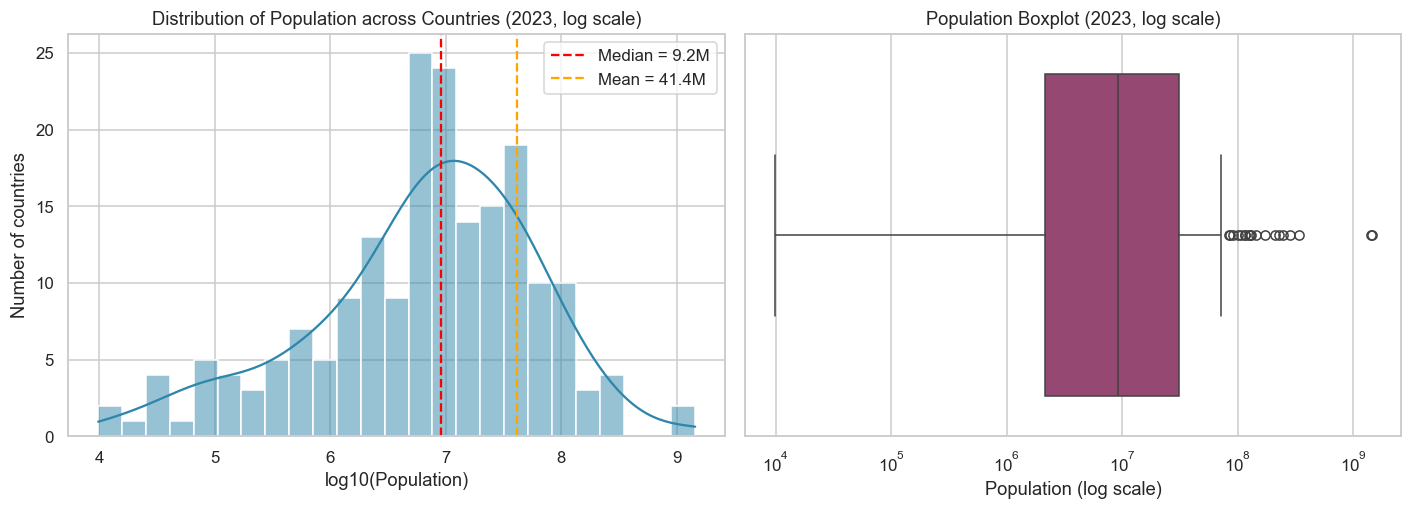

N = 194 countries


In [15]:
pop = df_ref["Population"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(np.log10(pop), bins=25, kde=True, color="#2E86AB", ax=axes[0])
axes[0].set_title(f"Distribution of Population across Countries ({REF_YEAR}, log scale)")
axes[0].set_xlabel("log10(Population)")
axes[0].set_ylabel("Number of countries")
axes[0].axvline(np.log10(pop.median()), color="red", ls="--", label=f"Median = {pop.median()/1e6:.1f}M")
axes[0].axvline(np.log10(pop.mean()), color="orange", ls="--", label=f"Mean = {pop.mean()/1e6:.1f}M")
axes[0].legend()

sns.boxplot(x=pop, color="#A23B72", ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title(f"Population Boxplot ({REF_YEAR}, log scale)")
axes[1].set_xlabel("Population (log scale)")

plt.tight_layout()
plt.savefig(CHARTS_DIR / "population_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"N = {len(pop)} countries")

**Interpretation (Chart 1):** Population size is extremely unequal across countries. The median country has about 9.2M people, while the mean is 41.4M, pulled up by a handful of giants (India and China, each above 1.4 billion). On a log scale the distribution is close to bell-shaped, with a long tail of micro-states (e.g., Tuvalu, Nauru, Palau) below 20 thousand people. N = 194 countries, 2023.

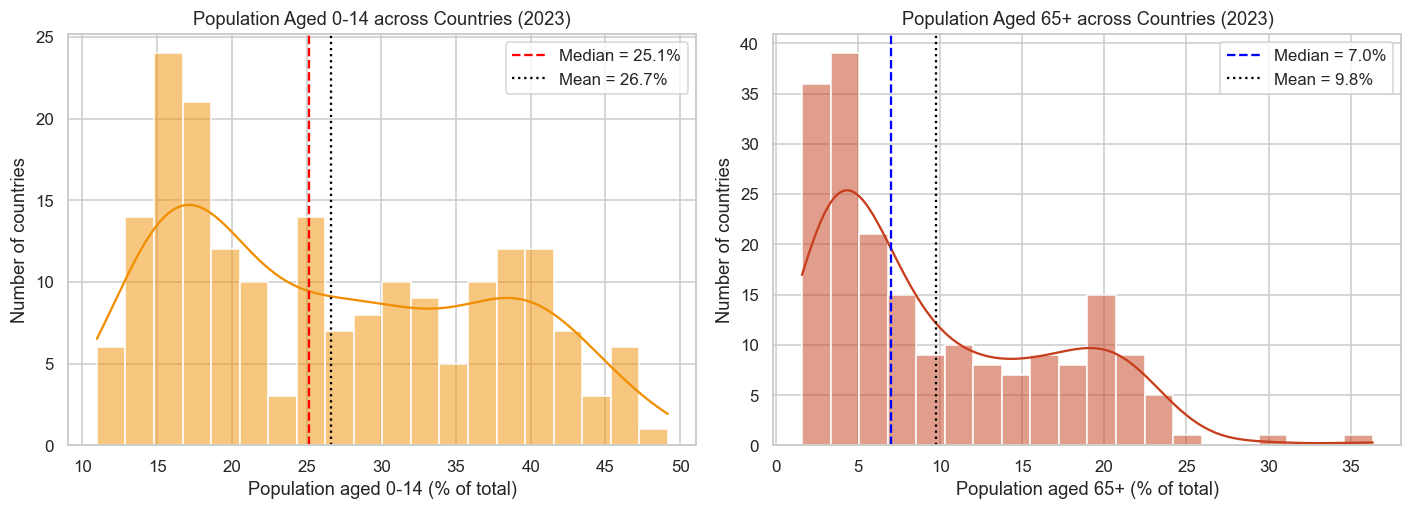

N = 194 countries (0-14), 194 countries (65+)


In [16]:
child = df_ref["Age_0_14_Pct"].dropna()
elder = df_ref["Age_65_Plus_Pct"].dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(child, bins=20, kde=True, color="#F18F01", ax=axes[0])
axes[0].axvline(child.median(), color="red", ls="--", label=f"Median = {child.median():.1f}%")
axes[0].axvline(child.mean(), color="black", ls=":", label=f"Mean = {child.mean():.1f}%")
axes[0].set_title(f"Population Aged 0-14 across Countries ({REF_YEAR})")
axes[0].set_xlabel("Population aged 0-14 (% of total)")
axes[0].set_ylabel("Number of countries")
axes[0].legend()

sns.histplot(elder, bins=20, kde=True, color="#C73E1D", ax=axes[1])
axes[1].axvline(elder.median(), color="blue", ls="--", label=f"Median = {elder.median():.1f}%")
axes[1].axvline(elder.mean(), color="black", ls=":", label=f"Mean = {elder.mean():.1f}%")
axes[1].set_title(f"Population Aged 65+ across Countries ({REF_YEAR})")
axes[1].set_xlabel("Population aged 65+ (% of total)")
axes[1].set_ylabel("Number of countries")
axes[1].legend()

plt.tight_layout()
plt.savefig(CHARTS_DIR / "age_structure_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"N = {len(child)} countries (0-14), {len(elder)} countries (65+)")

**Interpretation (Charts 2 & 3):** The age structure of countries splits into distinct groups. The share of children (0-14) is bimodal: one cluster around 15-17% and another around 38-40%, so the median (25.1%) falls in the sparse gap between two very different groups of countries. In contrast, the share of elderly (65+) is strongly right-skewed: most countries have under 8% (median 7.0%), while a small group of aging countries sits near 20% and two extremes (Japan, Monaco) exceed 29%. N = 194 countries, 2023.

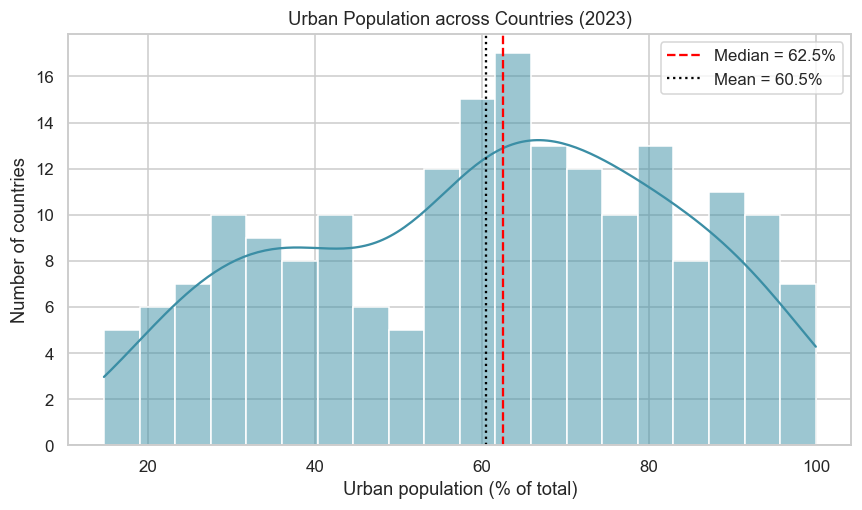

N = 194 countries


In [17]:
urban = df_ref["Urban_Population_Pct"].dropna()

fig, ax = plt.subplots(figsize=(8, 4.8))
sns.histplot(urban, bins=20, kde=True, color="#3B8EA5", ax=ax)
ax.axvline(urban.median(), color="red", ls="--", label=f"Median = {urban.median():.1f}%")
ax.axvline(urban.mean(), color="black", ls=":", label=f"Mean = {urban.mean():.1f}%")
ax.set_title(f"Urban Population across Countries ({REF_YEAR})")
ax.set_xlabel("Urban population (% of total)")
ax.set_ylabel("Number of countries")
ax.legend()

plt.tight_layout()
plt.savefig(CHARTS_DIR / "urbanization_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"N = {len(urban)} countries")

**Interpretation (Chart 4):** Urbanization varies widely, from about 15% to 100%, with no single dominant peak. The median country is about 62.5% urban (mean 60.5%). Five countries are 100% urban (Nauru, Monaco, Kuwait, Bahrain, Singapore), which is plausible for city-states and very small countries. N = 194 countries, 2023.

### Part C Summary

- **Largest populations (2023):** India, China, United States, Indonesia, Pakistan, Nigeria, Brazil, Bangladesh, Russia, Mexico.
- **Youngest populations (highest 0-14 %):** Central African Republic, Niger, Chad, Somalia, Mali.
- **Oldest populations (highest 65+ %):** Monaco, Japan, Italy, Portugal, Finland.
- **Most urbanized:** Nauru, Monaco, Kuwait, Bahrain, Singapore (all 100%).

---

## Part D: Time-Series Analysis

In [18]:
cols_ts = ["Population", "Age_0_14_Pct", "Age_65_Plus_Pct", "Urban_Population_Pct"]
ts_data = df.dropna(subset=cols_ts).copy()

def yearly_stats(g):
    w = g["Population"]
    return pd.Series({
        "N_Countries": g["ISO3"].nunique(),
        "Total_Population": w.sum(),
        "Age_0_14_Weighted": np.average(g["Age_0_14_Pct"], weights=w),
        "Age_65_Plus_Weighted": np.average(g["Age_65_Plus_Pct"], weights=w),
        "Urban_Weighted": np.average(g["Urban_Population_Pct"], weights=w),
        "Age_0_14_Mean": g["Age_0_14_Pct"].mean(),
        "Age_65_Plus_Mean": g["Age_65_Plus_Pct"].mean(),
        "Urban_Mean": g["Urban_Population_Pct"].mean(),
    })

yearly_ts = ts_data.groupby("Year").apply(yearly_stats)

print("Countries per year (min / max):", int(yearly_ts["N_Countries"].min()), "/", int(yearly_ts["N_Countries"].max()))
display(yearly_ts.loc[[1960, 1970, 1980, 1990, 2000, 2010, 2020, 2023, 2025]])

Countries per year (min / max): 193 / 194


,N_Countries,Total_Population,Age_0_14_Weighted,Age_65_Plus_Weighted,Urban_Weighted,Age_0_14_Mean,Age_65_Plus_Mean,Urban_Mean
Year,,,,,,,,
1960,193.000,"3,003,406,460.000",37.364,4.982,34.113,38.904,4.907,34.152
1970,193.000,"3,656,741,381.000",37.717,5.290,36.302,39.359,5.258,40.184
1980,193.000,"4,408,454,628.000",35.518,5.813,39.273,37.136,5.804,45.666
1990,194.000,"5,265,702,113.000",33.075,6.069,42.607,35.435,6.053,50.099
2000,194.000,"6,125,011,087.000",30.441,6.822,46.632,32.677,6.778,53.060
2010,194.000,"6,962,855,563.000",27.349,7.559,51.589,29.184,7.596,56.500
2020,194.000,"7,815,165,202.000",25.892,9.297,56.312,27.431,9.199,59.651
2023,194.000,"8,024,556,911.000",25.104,9.939,57.188,26.656,9.760,60.494
2025,194.000,"8,177,226,143.000",24.467,10.355,57.706,26.007,10.251,61.049


In [19]:
start, end = 1960, 2023
change = pd.DataFrame({
    f"{start}": yearly_ts.loc[start],
    f"{end}": yearly_ts.loc[end],
})
change["Change"] = change[f"{end}"] - change[f"{start}"]
change["Pct_Change"] = (change["Change"] / change[f"{start}"] * 100).round(1)
display(change.drop(index=["N_Countries"]))

,1960,2023,Change,Pct_Change
Total_Population,"3,003,406,460.000","8,024,556,911.000","5,021,150,451.000",167.200
Age_0_14_Weighted,37.364,25.104,-12.260,-32.800
Age_65_Plus_Weighted,4.982,9.939,4.958,99.500
Urban_Weighted,34.113,57.188,23.075,67.600
Age_0_14_Mean,38.904,26.656,-12.248,-31.500
Age_65_Plus_Mean,4.907,9.760,4.852,98.900
Urban_Mean,34.152,60.494,26.343,77.100


**Interpretation (Global trends, 1960-2023):** Between 1960 and 2023, the combined population of the countries in the dataset grew from about 3.0 to 8.0 billion (+167%). The population-weighted share of children (0-14) fell by 12.3 percentage points (37.4% to 25.1%), while the share aged 65+ roughly doubled (5.0% to 9.9%). The share living in urban areas rose by 23.1 percentage points (34.1% to 57.2%). Between 193 and 194 countries are included in every year, so these trends are not driven by changes in country coverage. The population-weighted urbanization level in 2023 (57.2%) is lower than the unweighted country mean (60.5%), because several very populous countries are less urbanized than the typical country.

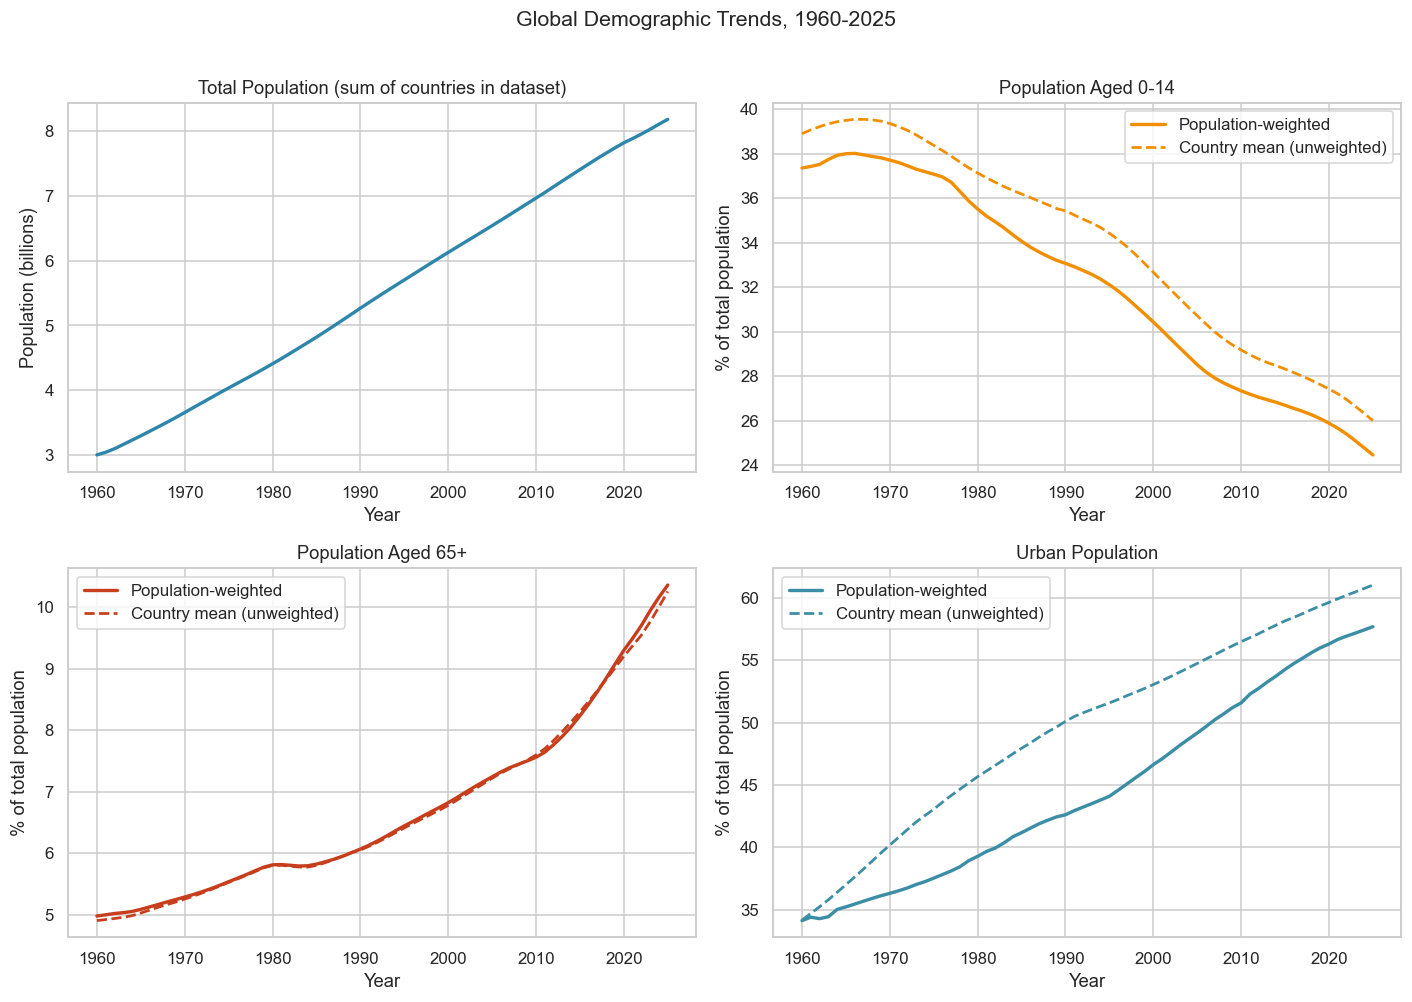

Countries per year: 193-194


In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Total population
axes[0, 0].plot(yearly_ts.index, yearly_ts["Total_Population"] / 1e9, color="#2E86AB", lw=2.2)
axes[0, 0].set_title("Total Population (sum of countries in dataset)")
axes[0, 0].set_ylabel("Population (billions)")

# 2-4) Percent indicators: weighted vs unweighted
panels = [
    (axes[0, 1], "Age_0_14", "Population Aged 0-14", "#F18F01"),
    (axes[1, 0], "Age_65_Plus", "Population Aged 65+", "#C73E1D"),
    (axes[1, 1], "Urban", "Urban Population", "#3B8EA5"),
]
for ax, key, title, color in panels:
    ax.plot(yearly_ts.index, yearly_ts[f"{key}_Weighted"], color=color, lw=2.2, label="Population-weighted")
    ax.plot(yearly_ts.index, yearly_ts[f"{key}_Mean"], color=color, lw=1.8, ls="--", label="Country mean (unweighted)")
    ax.set_title(title)
    ax.set_ylabel("% of total population")
    ax.legend()

for ax in axes.flat:
    ax.set_xlabel("Year")

fig.suptitle("Global Demographic Trends, 1960-2025", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "demographic_trends.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Countries per year: {int(yearly_ts['N_Countries'].min())}-{int(yearly_ts['N_Countries'].max())}")

**Interpretation (Chart 5):** Global demographics changed steadily between 1960 and 2025. The combined population of the dataset's countries rose from about 3.0 to 8.2 billion. The share of children (0-14) peaked in the mid-1960s and has declined since, with a faster drop after 1990. The share aged 65+ rose slowly until about 2010 and has accelerated since. Urbanization increased throughout the period. The population-weighted urban share stays below the unweighted country mean, because several very populous countries are less urbanized than the typical country. Countries per year: 193-194.

### Part D Summary

- Population (194 countries in dataset): 3.0B (1960) to 8.0B (2023), +167%.
- Children (0-14, population-weighted): 37.4% to 25.1% (-12.3 percentage points).
- Elderly (65+, population-weighted): 5.0% to 9.9% (roughly doubled); growth accelerates after 2010.
- Urbanization (population-weighted): 34.1% to 57.2% (+23.1 percentage points).
- Country coverage was 193-194 every year; nothing was imputed or interpolated.

---

## Part E: Demographic Indicators vs. UHC

**Design:** All comparisons use the 2023 cross-section (latest year with UHC data) so that every country is measured in the same year. Population is analyzed as log10(Population) because of its strong skew. Correlation uses both Pearson and Spearman. Correlation does not imply causation.

In [21]:
e = df_ref[["ISO3", "Country", "Population", "Age_0_14_Pct", "Age_65_Plus_Pct",
            "Urban_Population_Pct", UHC_COL]].copy()
e["Log10_Population"] = np.log10(e["Population"])

pairs = {
    "Urban_Population_Pct": "Urbanization (%)",
    "Age_65_Plus_Pct": "Elderly share 65+ (%)",
    "Age_0_14_Pct": "Children share 0-14 (%)",
    "Log10_Population": "log10(Population)",
}

rows = []
for col, label in pairs.items():
    sub = e[[col, UHC_COL, "ISO3"]].dropna()
    r, p_r = stats.pearsonr(sub[col], sub[UHC_COL])
    rho, p_s = stats.spearmanr(sub[col], sub[UHC_COL])
    rows.append({
        "Indicator": label,
        "N_Obs": len(sub),
        "N_Countries": sub["ISO3"].nunique(),
        "Pearson_r": r, "Pearson_p": p_r,
        "Spearman_rho": rho, "Spearman_p": p_s,
    })

corr_table = pd.DataFrame(rows).set_index("Indicator")
display(corr_table)

,N_Obs,N_Countries,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
Indicator,,,,,,
Urbanization (%),193,193,0.599,0.000,0.628,0.000
Elderly share 65+ (%),193,193,0.673,0.000,0.749,0.000
Children share 0-14 (%),193,193,-0.859,0.000,-0.830,0.000
log10(Population),193,193,-0.084,0.243,-0.033,0.652


**Interpretation (Correlations, 2023, N = 193 countries each):** The share of children (0-14) has a strong negative correlation with UHC (Pearson r = -0.86, Spearman ρ = -0.83, p < 0.001). The share aged 65+ (r = 0.67, ρ = 0.75) and urbanization (r = 0.60, ρ = 0.63) are positively correlated with UHC (both p < 0.001). Population size (log10) shows no meaningful correlation with UHC (r = -0.08, p = 0.24; ρ = -0.03, p = 0.65). Spearman and Pearson agree in direction and approximate strength, so the results are not driven by outliers. **These are associations only, not evidence of causation:** the demographic indicators are themselves strongly related to overall development and income, which likely drive both demographic structure and health coverage.

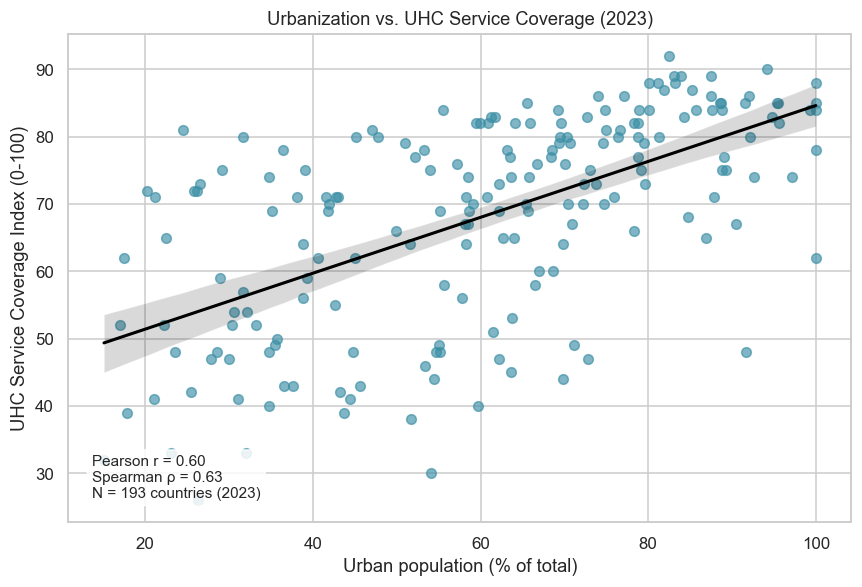

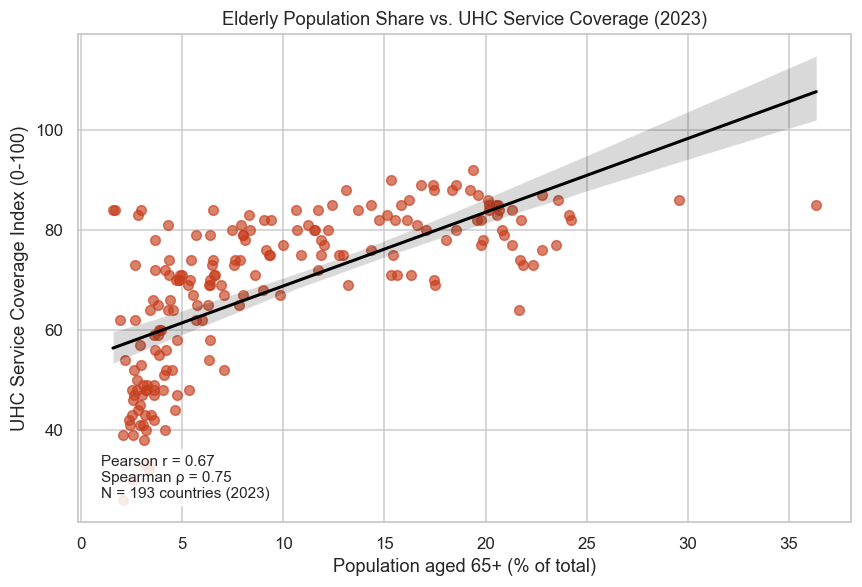

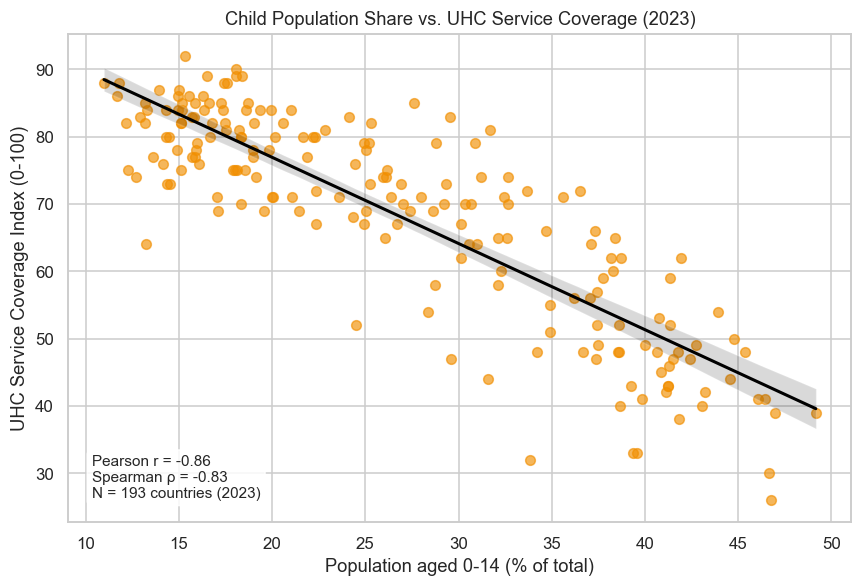

In [22]:
def scatter_vs_uhc(col, xlabel, title, fname, color, label_top=True):
    sub = e[["ISO3", "Country", col, UHC_COL]].dropna()
    r, p = stats.pearsonr(sub[col], sub[UHC_COL])
    rho, _ = stats.spearmanr(sub[col], sub[UHC_COL])

    fig, ax = plt.subplots(figsize=(8, 5.5))
    sns.regplot(data=sub, x=col, y=UHC_COL, ax=ax,
                scatter_kws={"alpha": 0.65, "s": 40, "color": color},
                line_kws={"color": "black", "lw": 2})
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("UHC Service Coverage Index (0-100)")
    ax.text(0.03, 0.05,
            f"Pearson r = {r:.2f}\nSpearman ρ = {rho:.2f}\nN = {len(sub)} countries (2023)",
            transform=ax.transAxes, fontsize=10,
            bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))
    plt.tight_layout()
    plt.savefig(CHARTS_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()

scatter_vs_uhc("Urban_Population_Pct", "Urban population (% of total)",
               "Urbanization vs. UHC Service Coverage (2023)",
               "urbanization_vs_uhc.png", "#3B8EA5")

scatter_vs_uhc("Age_65_Plus_Pct", "Population aged 65+ (% of total)",
               "Elderly Population Share vs. UHC Service Coverage (2023)",
               "elderly_population_vs_uhc.png", "#C73E1D")

scatter_vs_uhc("Age_0_14_Pct", "Population aged 0-14 (% of total)",
               "Child Population Share vs. UHC Service Coverage (2023)",
               "child_population_vs_uhc.png", "#F18F01")

**Interpretation (Charts 7, 8 & 9; 2023, N = 193 countries each):**

- **Urbanization vs. UHC (r = 0.60, ρ = 0.63):** Countries with a higher urban share tend to have higher UHC coverage, but the scatter is wide: at a given level of urbanization (e.g., 60-70%) UHC ranges from about 40 to 85, so urbanization alone explains only part of the variation.
- **Elderly share vs. UHC (r = 0.67, ρ = 0.75):** The association is positive but non-linear: UHC rises steeply between roughly 2% and 10% elderly share and flattens at higher shares. The fitted line extends above 100 at the right edge only because it is a linear extrapolation; UHC is capped at 100. Japan and Monaco lie far from the rest of the countries on the horizontal axis.
- **Child share vs. UHC (r = -0.86, ρ = -0.83):** This is the strongest and most linear relationship. Countries with about 15% children typically score 75-90 on UHC, while those above 40% typically score 30-55.

These are associations, not causal effects. All three age and urbanization indicators are closely tied to a country's overall development level, which likely affects both demographics and health coverage.

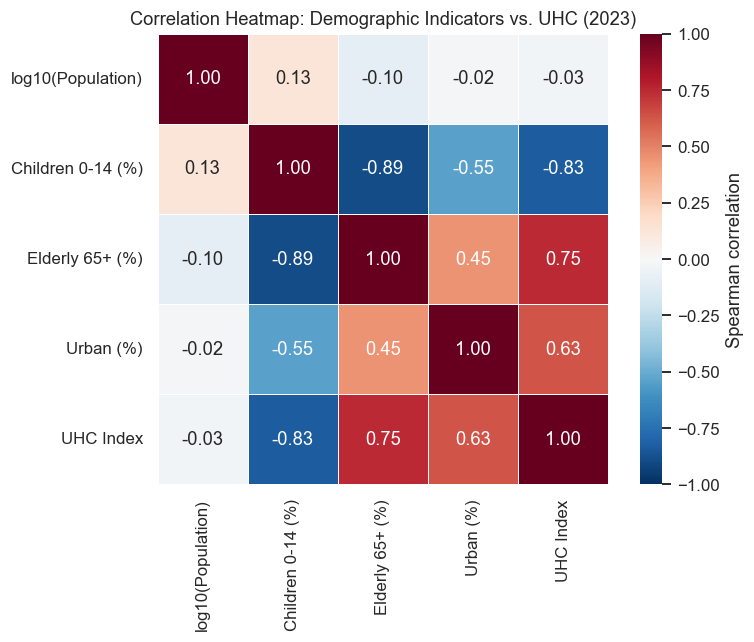

N = 193 countries (complete cases, 2023); Spearman correlation


In [23]:
heat_cols = ["Log10_Population", "Age_0_14_Pct", "Age_65_Plus_Pct", "Urban_Population_Pct", UHC_COL]
heat_labels = ["log10(Population)", "Children 0-14 (%)", "Elderly 65+ (%)", "Urban (%)", "UHC Index"]

heat_data = e[heat_cols].dropna()
corr_s = heat_data.corr(method="spearman")
corr_s.index = corr_s.columns = heat_labels

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_s, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title(f"Correlation Heatmap: Demographic Indicators vs. UHC ({REF_YEAR})")
plt.tight_layout()
plt.savefig(CHARTS_DIR / "demographic_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"N = {len(heat_data)} countries (complete cases, {REF_YEAR}); Spearman correlation")

**Interpretation (Chart 10; Spearman, 2023, N = 193 countries, complete cases):** UHC is most strongly associated with the share of children (ρ = -0.83), followed by the share of elderly (ρ = 0.75) and urbanization (ρ = 0.63); population size is essentially unrelated (ρ = -0.03). The demographic indicators are also strongly related to each other (children vs. elderly ρ = -0.89; children vs. urban ρ = -0.55; elderly vs. urban ρ = 0.45), so they largely capture the same underlying pattern of demographic transition and development level. Their associations with UHC therefore cannot be interpreted as independent effects, and none of these correlations establish causation.

### Part E Summary

All comparisons use 2023 (N = 193 countries).
- **Children 0-14 vs. UHC:** strong negative (r = -0.86, ρ = -0.83).
- **Elderly 65+ vs. UHC:** positive, non-linear (r = 0.67, ρ = 0.75).
- **Urbanization vs. UHC:** positive, widely scattered (r = 0.60, ρ = 0.63).
- **Population size vs. UHC:** no meaningful association (r = -0.08, p = 0.24).
- The demographic indicators are strongly intercorrelated; associations are not causal.

---

## Part F: Cross-Country Comparison

In [24]:
latest = {}
for c in DEMO_COLS:
    s = df.dropna(subset=[c]).sort_values("Year").groupby("ISO3").tail(1)
    latest[c] = s.set_index("ISO3")[["Country", "Year", c]]

for c in DEMO_COLS:
    print(f"{c}: latest year = {latest[c]['Year'].mode()[0]} "
          f"(countries: {len(latest[c])}, "
          f"countries not at 2025: {(latest[c]['Year'] != 2025).sum()})")

def extremes(col, n=10):
    d = latest[col].reset_index().sort_values(col, ascending=False)
    return d.head(n).reset_index(drop=True), d.tail(n).iloc[::-1].reset_index(drop=True)

top_pop, _ = extremes("Population", 10)
print("\nTop 10 by Population (latest year)")
display(top_pop)

for col, label in [("Urban_Population_Pct", "Urban %"),
                   ("Age_65_Plus_Pct", "Age 65+ %"),
                   ("Age_0_14_Pct", "Age 0-14 %")]:
    hi, lo = extremes(col, 5)
    print(f"\n{label}: Highest 5")
    display(hi)
    print(f"{label}: Lowest 5")
    display(lo)

Population: latest year = 2025 (countries: 194, countries not at 2025: 0)
Age_0_14_Pct: latest year = 2025 (countries: 194, countries not at 2025: 0)
Age_65_Plus_Pct: latest year = 2025 (countries: 194, countries not at 2025: 0)
Urban_Population_Pct: latest year = 2025 (countries: 194, countries not at 2025: 0)

Top 10 by Population (latest year)


,ISO3,Country,Year,Population
0,IND,India,2025,"1,463,865,525.000"
1,CHN,China,2025,"1,406,585,000.000"
2,USA,United States,2025,"341,784,857.000"
3,IDN,Indonesia,2025,"285,721,236.000"
4,PAK,Pakistan,2025,"255,219,554.000"
5,NGA,Nigeria,2025,"237,527,782.000"
6,BRA,Brazil,2025,"212,812,405.000"
7,BGD,Bangladesh,2025,"175,686,899.000"
8,RUS,Russian Federation,2025,"143,513,328.000"
9,ETH,Ethiopia,2025,"135,472,051.000"



Urban %: Highest 5


,ISO3,Country,Year,Urban_Population_Pct
0,KWT,Kuwait,2025,100.000
1,BHR,Bahrain,2025,100.000
2,MCO,Monaco,2025,100.000
3,NRU,Nauru,2025,100.000
4,SGP,Singapore,2025,100.000


Urban %: Lowest 5


,ISO3,Country,Year,Urban_Population_Pct
0,LIE,Liechtenstein,2025,14.630
1,PNG,Papua New Guinea,2025,15.780
2,WSM,Samoa,2025,17.506
3,MWI,Malawi,2025,17.595
4,NER,Niger,2025,18.374


... (4 outputs left out)


Age 0-14 %: Highest 5


,ISO3,Country,Year,Age_0_14_Pct
0,CAF,Central African Republic,2025,48.683
1,SOM,Somalia,2025,46.554
2,NER,Niger,2025,46.226
3,TCD,Chad,2025,45.962
4,COD,"Congo, The Democratic Republic of the",2025,45.950


Age 0-14 %: Lowest 5


,ISO3,Country,Year,Age_0_14_Pct
0,KOR,"Korea, Republic of",2025,10.204
1,JPN,Japan,2025,11.238
2,AND,Andorra,2025,11.618
3,ITA,Italy,2025,11.657
4,SGP,Singapore,2025,11.689


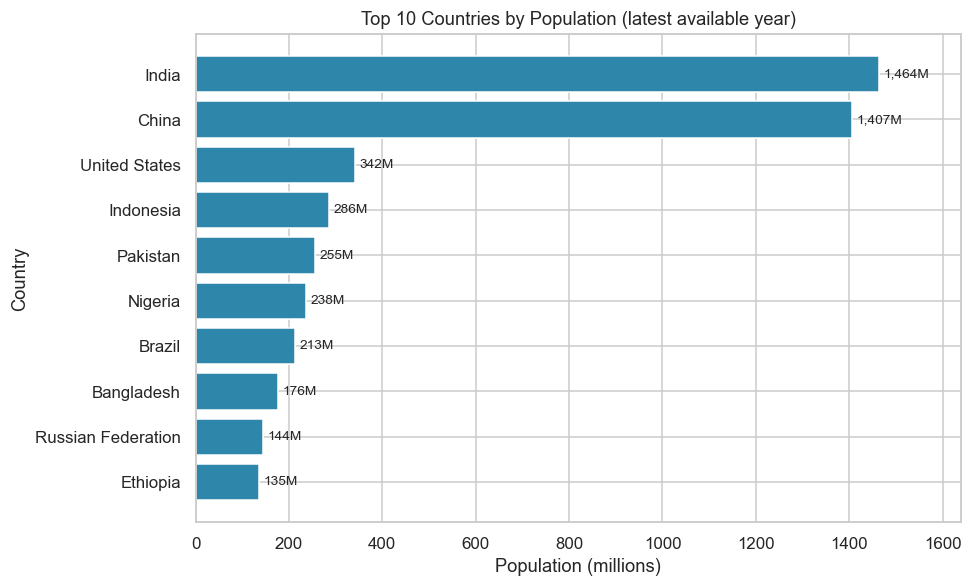

Year(s) used: [np.int64(2025)]


In [25]:
top10 = top_pop.sort_values("Population")

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top10["Country"], top10["Population"] / 1e6, color="#2E86AB")
for i, v in enumerate(top10["Population"] / 1e6):
    ax.text(v + 10, i, f"{v:,.0f}M", va="center", fontsize=9)
ax.set_title("Top 10 Countries by Population (latest available year)")
ax.set_xlabel("Population (millions)")
ax.set_ylabel("Country")
ax.set_xlim(0, top10["Population"].max() / 1e6 * 1.12)
plt.tight_layout()
plt.savefig(CHARTS_DIR / "top_10_population.png", dpi=150, bbox_inches="tight")
plt.show()
print("Year(s) used:", sorted(top_pop["Year"].unique()))

**Interpretation (Chart 6):** India (about 1.46 billion) and China (about 1.41 billion) are far ahead of every other country; together they exceed the next eight combined? No: they are each more than four times larger than the third-largest country, the United States (about 342 million). Ethiopia (about 135 million) ranks tenth in 2025, ahead of Mexico, which was tenth in 2023. All values are 2025.

**Interpretation (Cross-country comparison, 2025, N = 194 countries):**
- **Population:** The ten largest countries are India, China, the United States, Indonesia, Pakistan, Nigeria, Brazil, Bangladesh, Russia, and Ethiopia.
- **Urbanization:** Kuwait, Bahrain, Monaco, Nauru, and Singapore are 100% urban; the least urbanized are Liechtenstein (14.6%), Papua New Guinea (15.8%), Samoa (17.5%), Malawi (17.6%), and Niger (18.4%).
- **Elderly (65+):** Highest in Monaco (36.0%), Japan (30.0%), Italy (25.1%), Portugal (24.9%), and Greece (24.4%); lowest in Qatar (1.7%), the UAE (1.8%), Zambia (2.0%), Chad (2.1%), and the Central African Republic (2.2%).
- **Children (0-14):** Highest in the Central African Republic (48.7%), Somalia (46.6%), Niger (46.2%), Chad (46.0%), and DR Congo (46.0%); lowest in South Korea (10.2%), Japan (11.2%), Andorra (11.6%), Italy (11.7%), and Singapore (11.7%).
- The latest year is 2025 for all 194 countries, so no cross-year adjustment was needed. Comparisons with UHC remain at 2023.

In [26]:
summary_parts = []

# 1) Descriptive stats (2023)
d = desc_2023.reset_index()
d.insert(0, "Section", "Descriptive_2023")
summary_parts.append(d.rename(columns={"Indicator": "Item"}))

# 2) Correlations with UHC (2023)
c = corr_table.reset_index().rename(columns={"Indicator": "Item"})
c.insert(0, "Section", "Correlation_with_UHC_2023")
summary_parts.append(c)

# 3) Global trends 1960 vs 2023
t = change.reset_index().rename(columns={"index": "Item"})
t.insert(0, "Section", "Global_Trend_1960_vs_2023")
summary_parts.append(t)

# 4) Cross-country comparison (latest year)
rows = []
for col in DEMO_COLS:
    d_ = latest[col].reset_index().sort_values(col, ascending=False)
    n = 10 if col == "Population" else 5
    for rank, r_ in enumerate(d_.head(n).itertuples(index=False), 1):
        rows.append({"Section": "Cross_Country_Highest", "Item": col, "Rank": rank,
                     "ISO3": r_.ISO3, "Country": r_.Country, "Year": r_.Year, "Value": getattr(r_, col)})
    if col != "Population":
        for rank, r_ in enumerate(d_.tail(5).iloc[::-1].itertuples(index=False), 1):
            rows.append({"Section": "Cross_Country_Lowest", "Item": col, "Rank": rank,
                         "ISO3": r_.ISO3, "Country": r_.Country, "Year": r_.Year, "Value": getattr(r_, col)})
summary_parts.append(pd.DataFrame(rows))

summary = pd.concat(summary_parts, ignore_index=True)
summary.to_csv("demographic_analysis_summary.csv", index=False)
print(summary.shape)
display(summary.groupby("Section").size())

(57, 26)


Section
Correlation_with_UHC_2023     4
Cross_Country_Highest        25
Cross_Country_Lowest         15
Descriptive_2023              5
Global_Trend_1960_vs_2023     8
dtype: int64